# Comparing Solutions to Spam Email Detections

- Author: Jovan Heng Ghim Hong

**Goal:** Can simple models like BoW/TF-IDF + MLP outperform complex models like BERT + LSTM for spam email detection?

**How is comparison done?**

- We evaluate the following metrics
  - Recall (Spm Detection Rate)
  - Model Size
  - Training Time
  - Inference Time

- Note that all models are trained and evaluated on the same dataset for a fair comparison.

## BoW and TF-IDF Implementation for Spam Email Detection

I want to try to build a simple spam email detector. For now I will try to implement BoW and TF-IDF as a more lightweight alternative to word embeddings.

Since BoW and TF-IDF remove word order, a simple MLP should be sufficient, removing the need for a order based RNN like LSTM or GRU.

In [245]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [246]:
#imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
np.random.seed(42)

from sklearn.model_selection import train_test_split, StratifiedKFold, ParameterSampler
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, recall_score

from nltk.tokenize import word_tokenize

from src.eda import clean_text, remove_stopwords, lemmatize_reviews
from src.utils import timer
from src.model import Model, train_kf

In [247]:
# import the dataset
data = pd.read_csv('dataset/email.csv')
X = data['Message'].values
y = [0 if l == 'ham' else 1 for l in data['Category'].values]

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [248]:
# here we clean the text and prepare it for vectorization
X_train = [remove_stopwords(clean_text(text)) for text in X_train]
X_test = [remove_stopwords(clean_text(text)) for text in X_test]

# for a simple model like BoW or TF-IDF lemmatization typically helps
X_train_lematized = [lemmatize_reviews(text) for text in X_train]
X_test_lematized = [lemmatize_reviews(text) for text in X_test]

In [249]:
_ , (ham_count, spam_count) = np.unique(y_train, return_counts=True)
print(f'Ham Count: {ham_count/len(y_train)*100:.2f}%')
print(f'Spam Count: {spam_count/len(y_train)*100:.2f}%')

Ham Count: 86.59%
Spam Count: 13.41%


In [250]:
# we will use class weights to handle class imbalance
class_weights = torch.tensor([len(y_train)/(2*ham_count), len(y_train)/(2*spam_count)], dtype=torch.float)

### Binary Bag of Words

In [251]:
# we will still try to implement on a lemmatized dataset with both BoW and TF-IDF
bow_vectorizer = CountVectorizer(tokenizer=word_tokenize, binary=True, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = bow_vectorizer.fit_transform(X_train)
X_test_sequences = bow_vectorizer.transform(X_test)

X_lemmatized_sequences = bow_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = bow_vectorizer.transform(X_test_lematized)

In [252]:
## Prepare DataLoaders
## Original
binary_bow_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_x_train_loader = DataLoader(binary_bow_x_train, batch_size=32, shuffle=True)
binary_bow_x_test_loader = DataLoader(binary_bow_x_test, batch_size=32)

## lematized
# in theory lematization should help with BoW/TF-IDF
binary_bow_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
binary_bow_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

binary_bow_lematized_x_train_loader = DataLoader(binary_bow_lematized_x_train, batch_size=32, shuffle=True)
binary_bow_lematized_x_test_loader = DataLoader(binary_bow_lematized_x_test, batch_size=32)

In [253]:
# we build a simple linear model
class LinearModel(Model):
  def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.5):
    super().__init__()
    # since the inputs are BoW/TF-IDF vectors, we can use a simple feedforward neural network
    self.fc1 = nn.Linear(input_dim, hidden_dim)
    self.relu = nn.ReLU()
    self.dropout = nn.Dropout(dropout_rate)
    self.fc2 = nn.Linear(hidden_dim, output_dim)
    self.accuracy_history = []
    self.loss_history = []
  
  def forward(self, x):
    out = self.fc1(x)
    out = self.relu(out)
    out = self.fc2(out)
    return out


In [254]:
# here we will define a hyper parameter space for the MLP

param_space = {
    'input_dim': [X_sequences.shape[1], X_lemmatized_sequences.shape[1]],
    'hidden_dim': [4, 8, 16, 32],
    'output_dim': [2],
    'lr': [1e-2, 1e-3, 1e-4],
    'batch_size': [16, 32, 64, 128],
    'epochs': [10, 20, 30, 40],
    'dropout_rate': [0.3, 0.5, 0.7]
}

selected_params = list(ParameterSampler(param_space, n_iter=5, random_state=42))

In [255]:
# we will train 2 models: one on the original data and one on the lemmatized data
# we will be using stratified kf cv

# original_data
binary_bow_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in selected_params:
  print(f'Training Binary BoW with params: {params}')


  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=binary_bow_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
)

  binary_bow_results.append({
    **params,
    **results
  })

  
# lemmatized data
lemmatized_bow_results = []
for params in selected_params:
  print(f'Training Binary BoW Lemmatized with params: {params}')
  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=binary_bow_lematized_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
)

  lemmatized_bow_results.append({
    **params,
    **results
  })

Training Binary BoW with params: {'output_dim': 2, 'lr': 0.001, 'input_dim': 5000, 'hidden_dim': 32, 'epochs': 30, 'dropout_rate': 0.7, 'batch_size': 128}

Fold 1/5
Epoch 1/30, Loss: 0.6355, Accuracy: 52.47%
Epoch 2/30, Loss: 0.4240, Accuracy: 96.75%
Epoch 3/30, Loss: 0.2428, Accuracy: 98.60%
Epoch 4/30, Loss: 0.1505, Accuracy: 98.99%
Epoch 5/30, Loss: 0.1042, Accuracy: 99.30%
Epoch 6/30, Loss: 0.0766, Accuracy: 99.58%
Epoch 7/30, Loss: 0.0604, Accuracy: 99.64%
Epoch 8/30, Loss: 0.0486, Accuracy: 99.69%
Epoch 9/30, Loss: 0.0409, Accuracy: 99.72%
Epoch 10/30, Loss: 0.0359, Accuracy: 99.75%
Epoch 11/30, Loss: 0.0312, Accuracy: 99.78%
Epoch 12/30, Loss: 0.0275, Accuracy: 99.80%
Epoch 13/30, Loss: 0.0242, Accuracy: 99.80%
Epoch 14/30, Loss: 0.0222, Accuracy: 99.83%
Epoch 15/30, Loss: 0.0204, Accuracy: 99.83%
Epoch 16/30, Loss: 0.0190, Accuracy: 99.83%
Epoch 17/30, Loss: 0.0179, Accuracy: 99.86%
Epoch 18/30, Loss: 0.0164, Accuracy: 99.86%
Epoch 19/30, Loss: 0.0160, Accuracy: 99.89%
Epoch 20

In [256]:
binary_bow_results_df = pd.DataFrame(binary_bow_results).sort_values(by='f1', ascending=False)
lemmatized_bow_results_df = pd.DataFrame(lemmatized_bow_results).sort_values(by='f1', ascending=False)

display(binary_bow_results_df)
display(lemmatized_bow_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
3,2,0.0100,5000,16,20,0.7,128,0.949311,0.977369,0.962672,0.983176
0,2,0.0010,5000,32,30,0.7,128,0.946797,0.976932,0.961117,0.982504
4,2,0.0100,5000,16,40,0.5,128,0.945956,0.976857,0.960598,0.982279
2,2,0.0001,5000,4,40,0.7,128,0.941058,0.976919,0.957633,0.981157
1,2,0.0001,5000,32,40,0.7,64,0.943117,0.968704,0.955335,0.979812


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
2,2,0.0001,5000,4,40,0.7,128,0.951671,0.971496,0.960943,0.982281
0,2,0.0010,5000,32,30,0.7,128,0.945123,0.976569,0.960053,0.982055
4,2,0.0100,5000,16,40,0.5,128,0.946415,0.974312,0.959732,0.981831
3,2,0.0100,5000,16,20,0.7,128,0.944885,0.974828,0.959114,0.981607
1,2,0.0001,5000,32,40,0.7,64,0.940494,0.967245,0.953287,0.978915


From the hyper parameter tuning, the best parameters are as follows:

**Original BoW:**

| Hyperparameter | Value |
|----------------|-------|


In [257]:
# retraining on the best params
print('Training Baseline BoW Model')
with timer('Baseline BoW Model Training Time'):
  bow_best_params = binary_bow_results_df.iloc[0]

  # need to rebatch the data
  binary_bow_x_train_loader = DataLoader(binary_bow_x_train, batch_size=int(bow_best_params['batch_size']), shuffle=True)

  bow_best_model = LinearModel(
    input_dim=int(bow_best_params['input_dim']),
    hidden_dim=int(bow_best_params['hidden_dim']),
    output_dim=int(bow_best_params['output_dim']),
    dropout_rate=float(bow_best_params['dropout_rate'])
  )
  optimizer = Adam(bow_best_model.parameters(), lr=bow_best_params['lr'])
  bow_best_model.fit(int(bow_best_params['epochs']), binary_bow_x_train_loader, loss_fn, optimizer, early_stop=True)

print()
print('Training Baseline Lemmatized BoW Model')
with timer('Baseline Lemmatized BoW Model Training Time'):
  lemmatized_bow_best_params = lemmatized_bow_results_df.iloc[0]

  # need to rebatch the data
  binary_bow_lematized_x_train_loader = DataLoader(binary_bow_lematized_x_train, batch_size=int(lemmatized_bow_best_params['batch_size']), shuffle=True)

  lemmatized_bow_best_model = LinearModel(
    input_dim=int(lemmatized_bow_best_params['input_dim']),
    hidden_dim=int(lemmatized_bow_best_params['hidden_dim']),
    output_dim=int(lemmatized_bow_best_params['output_dim']),
    dropout_rate=float(lemmatized_bow_best_params['dropout_rate'])
  )
  optimizer = Adam(lemmatized_bow_best_model.parameters(), lr=lemmatized_bow_best_params['lr'])
  lemmatized_bow_best_model.fit(int(lemmatized_bow_best_params['epochs']), binary_bow_lematized_x_train_loader, loss_fn, optimizer, early_stop=True)

Training Baseline BoW Model
Epoch 1/20, Loss: 0.3148, Accuracy: 94.75%
Epoch 2/20, Loss: 0.0573, Accuracy: 98.86%
Epoch 3/20, Loss: 0.0256, Accuracy: 99.69%
Epoch 4/20, Loss: 0.0169, Accuracy: 99.80%
Epoch 5/20, Loss: 0.0128, Accuracy: 99.84%
Epoch 6/20, Loss: 0.0119, Accuracy: 99.84%
Epoch 7/20, Loss: 0.0112, Accuracy: 99.84%
Epoch 8/20, Loss: 0.0099, Accuracy: 99.84%
Epoch 9/20, Loss: 0.0096, Accuracy: 99.84%
Epoch 10/20, Loss: 0.0089, Accuracy: 99.84%
Epoch 11/20, Loss: 0.0087, Accuracy: 99.84%
Epoch 12/20, Loss: 0.0091, Accuracy: 99.87%
Epoch 13/20, Loss: 0.0088, Accuracy: 99.84%
Epoch 14/20, Loss: 0.0086, Accuracy: 99.87%
Epoch 15/20, Loss: 0.0073, Accuracy: 99.87%
Epoch 16/20, Loss: 0.0076, Accuracy: 99.87%
Epoch 17/20, Loss: 0.0075, Accuracy: 99.87%
Epoch 18/20, Loss: 0.0072, Accuracy: 99.93%
Epoch 19/20, Loss: 0.0068, Accuracy: 99.96%
Epoch 20/20, Loss: 0.0072, Accuracy: 99.96%
Baseline BoW Model Training Time: 1.9940s

Training Baseline Lemmatized BoW Model
Epoch 1/40, Loss: 0

In [258]:
# saving weights
torch.save(bow_best_model.state_dict(), 'weights/bow_model.pth')
torch.save(lemmatized_bow_best_model.state_dict(), 'weights/lemmatized_bow_model.pth')

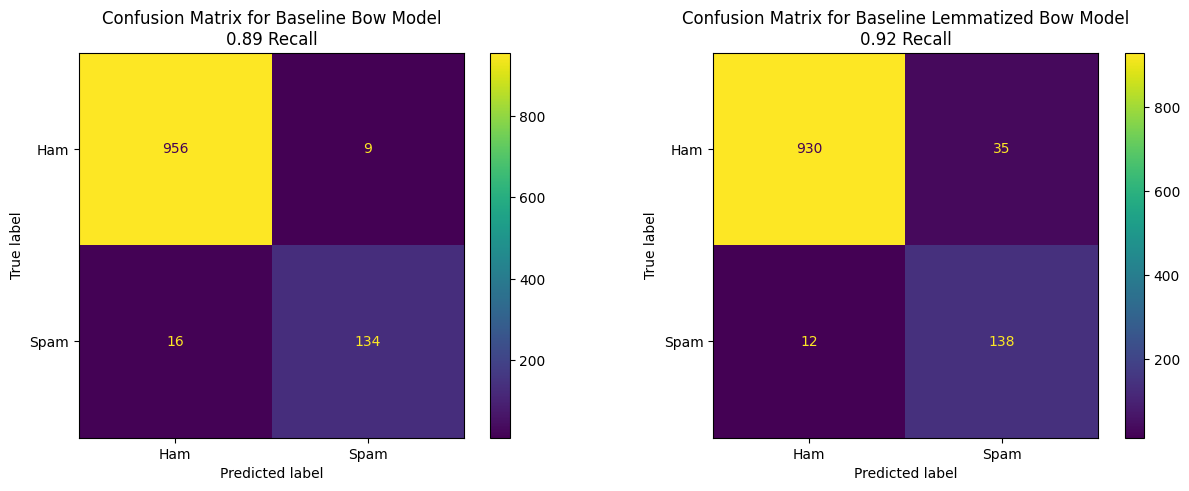

In [259]:
# loading weights
bow_best_model.load_state_dict(torch.load('weights/bow_model.pth'))
lemmatized_bow_best_model.load_state_dict(torch.load('weights/lemmatized_bow_model.pth'))

# get predictions (on test set)
baseline_bow_predictions = bow_best_model.predict(binary_bow_x_test_loader)
baseline_bow_lematized_predictions = lemmatized_bow_best_model.predict(binary_bow_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
baseline_bow_cm = confusion_matrix(y_test, baseline_bow_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline Bow Model\n{recall_score(y_test, baseline_bow_predictions, pos_label=1):.2f} Recall')

# lemmatized
baseline_bow_lematized_cm = confusion_matrix(y_test, baseline_bow_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=baseline_bow_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized Bow Model\n{recall_score(y_test, baseline_bow_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()

Here we see that such a simple model such as Binary BoW with a simple MLP can achieve a high recall on the spam emails.

The results here also show that lemmatization has almost no impact


--- 

### TF-IDF

In theory since TF-IDF takes into account word importance, it should perform better than BoW. 

In [260]:
tf_idf_vectorizer = TfidfVectorizer(tokenizer=word_tokenize, lowercase=True, max_features=5000, ngram_range=(1,2))
X_sequences = tf_idf_vectorizer.fit_transform(X_train)
X_test_sequences = tf_idf_vectorizer.transform(X_test)

X_lemmatized_sequences = tf_idf_vectorizer.fit_transform(X_train_lematized)
X_test_lemmatized_sequences = tf_idf_vectorizer.transform(X_test_lematized)

In [261]:
## Prepare DataLoaders
## Original
tf_idf_x_train = TensorDataset(torch.tensor(X_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_x_test = TensorDataset(torch.tensor(X_test_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_x_train_loader = DataLoader(tf_idf_x_train, batch_size=32, shuffle=True)
tf_idf_x_test_loader = DataLoader(tf_idf_x_test, batch_size=32)

## lematized
tf_idf_lematized_x_train = TensorDataset(torch.tensor(X_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_train))
tf_idf_lematized_x_test = TensorDataset(torch.tensor(X_test_lemmatized_sequences.toarray(), dtype=torch.float32), torch.tensor(y_test))

tf_idf_lematized_x_train_loader = DataLoader(tf_idf_lematized_x_train, batch_size=32, shuffle=True)
tf_idf_lematized_x_test_loader = DataLoader(tf_idf_lematized_x_test, batch_size=32)

In [262]:
# hyperparameter tuning for TF-IDF models (original and lemmatized)
tf_idf_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in selected_params:
  print(f'Training TF-IDF with params: {params}')

  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tf_idf_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
  )

  tf_idf_results.append({
    **params,
    **results
  })

# lemmatized data
tf_idf_lematized_results = []
for params in selected_params:
  print(f'Training TF-IDF Lemmatized with params: {params}')
  model = LinearModel
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tf_idf_lematized_x_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=5
  )

  tf_idf_lematized_results.append({
    **params,
    **results
  })

Training TF-IDF with params: {'output_dim': 2, 'lr': 0.001, 'input_dim': 5000, 'hidden_dim': 32, 'epochs': 30, 'dropout_rate': 0.7, 'batch_size': 128}

Fold 1/5
Epoch 1/30, Loss: 0.6804, Accuracy: 13.88%
Epoch 2/30, Loss: 0.5916, Accuracy: 79.30%
Epoch 3/30, Loss: 0.4510, Accuracy: 96.80%
Epoch 4/30, Loss: 0.3114, Accuracy: 98.15%
Epoch 5/30, Loss: 0.2116, Accuracy: 98.68%
Epoch 6/30, Loss: 0.1516, Accuracy: 98.91%
Epoch 7/30, Loss: 0.1147, Accuracy: 99.07%
Epoch 8/30, Loss: 0.0899, Accuracy: 99.24%
Epoch 9/30, Loss: 0.0732, Accuracy: 99.44%
Epoch 10/30, Loss: 0.0615, Accuracy: 99.44%
Epoch 11/30, Loss: 0.0523, Accuracy: 99.58%
Epoch 12/30, Loss: 0.0452, Accuracy: 99.61%
Epoch 13/30, Loss: 0.0392, Accuracy: 99.64%
Epoch 14/30, Loss: 0.0349, Accuracy: 99.69%
Epoch 15/30, Loss: 0.0312, Accuracy: 99.75%
Epoch 16/30, Loss: 0.0279, Accuracy: 99.80%
Epoch 17/30, Loss: 0.0254, Accuracy: 99.80%
Epoch 18/30, Loss: 0.0233, Accuracy: 99.80%
Epoch 19/30, Loss: 0.0215, Accuracy: 99.83%
Epoch 20/30,

In [263]:
tf_idf_results_df = pd.DataFrame(tf_idf_results).sort_values(by='f1', ascending=False)
tf_idf_lematized_results_df = pd.DataFrame(tf_idf_lematized_results).sort_values(by='f1', ascending=False)

display(tf_idf_results_df)
display(tf_idf_lematized_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0100,5000,16,40,0.5,128,0.952581,0.962014,0.957137,0.980261
0,2,0.0010,5000,32,30,0.7,128,0.951037,0.962470,0.956544,0.980037
1,2,0.0001,5000,32,40,0.7,64,0.950519,0.959264,0.954738,0.979140
3,2,0.0100,5000,16,20,0.7,128,0.950841,0.956298,0.953421,0.978466
2,2,0.0001,5000,4,40,0.7,128,0.947063,0.958165,0.952154,0.978018


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
0,2,0.0010,5000,32,30,0.7,128,0.955340,0.964037,0.959569,0.981382
4,2,0.0100,5000,16,40,0.5,128,0.955340,0.963976,0.959560,0.981382
1,2,0.0001,5000,32,40,0.7,64,0.953730,0.959099,0.956332,0.979813
3,2,0.0100,5000,16,20,0.7,128,0.953026,0.959814,0.956266,0.979811
2,2,0.0001,5000,4,40,0.7,128,0.957844,0.954860,0.956240,0.979588


In [264]:
print('Training Baseline TF-IDF Model')
with timer('Baseline TF-IDF Model Training Time'):
  tf_idf_best_params = tf_idf_results_df.iloc[0]

  # rebatch with best batch size
  tf_idf_x_train_loader = DataLoader(tf_idf_x_train, batch_size=int(tf_idf_best_params['batch_size']), shuffle=True)

  tf_idf_model = LinearModel(
    input_dim=int(tf_idf_best_params['input_dim']),
    hidden_dim=int(tf_idf_best_params['hidden_dim']),
    output_dim=int(tf_idf_best_params['output_dim']),
    dropout_rate=float(tf_idf_best_params['dropout_rate'])
  )
  tf_idf_optimizer = Adam(tf_idf_model.parameters(), lr=tf_idf_best_params['lr'])
  tf_idf_model.fit(int(tf_idf_best_params['epochs']), tf_idf_x_train_loader, loss_fn, tf_idf_optimizer, early_stop=True)

print()
print('Training Baseline Lemmatized TF-IDF Model')
with timer('Baseline Lemmatized TF-IDF Model Training Time'):
  tf_idf_lemmatized_best_params = tf_idf_lematized_results_df.iloc[0]

  # rebatch with best batch size
  tf_idf_lematized_x_train_loader = DataLoader(tf_idf_lematized_x_train, batch_size=int(tf_idf_lemmatized_best_params['batch_size']), shuffle=True)

  tf_idf_lemmatized_model = LinearModel(
    input_dim=int(tf_idf_lemmatized_best_params['input_dim']),
    hidden_dim=int(tf_idf_lemmatized_best_params['hidden_dim']),
    output_dim=int(tf_idf_lemmatized_best_params['output_dim']),
    dropout_rate=float(tf_idf_lemmatized_best_params['dropout_rate'])
  )
  tf_idf_lemmatized_optimizer = Adam(tf_idf_lemmatized_model.parameters(), lr=tf_idf_lemmatized_best_params['lr'])
  tf_idf_lemmatized_model.fit(int(tf_idf_lemmatized_best_params['epochs']), tf_idf_lematized_x_train_loader, loss_fn, tf_idf_lemmatized_optimizer, early_stop=True)

Training Baseline TF-IDF Model
Epoch 1/40, Loss: 0.3928, Accuracy: 79.70%
Epoch 2/40, Loss: 0.0628, Accuracy: 98.59%
Epoch 3/40, Loss: 0.0260, Accuracy: 99.57%
Epoch 4/40, Loss: 0.0143, Accuracy: 99.78%
Epoch 5/40, Loss: 0.0105, Accuracy: 99.87%
Epoch 6/40, Loss: 0.0088, Accuracy: 99.91%
Epoch 7/40, Loss: 0.0073, Accuracy: 99.93%
Epoch 8/40, Loss: 0.0065, Accuracy: 99.93%
Epoch 9/40, Loss: 0.0066, Accuracy: 99.96%
Epoch 10/40, Loss: 0.0063, Accuracy: 99.93%
Epoch 11/40, Loss: 0.0059, Accuracy: 99.96%
Epoch 12/40, Loss: 0.0059, Accuracy: 99.96%
Epoch 13/40, Loss: 0.0062, Accuracy: 99.96%
Epoch 14/40, Loss: 0.0055, Accuracy: 99.96%
Epoch 15/40, Loss: 0.0059, Accuracy: 99.96%
Epoch 16/40, Loss: 0.0061, Accuracy: 99.96%
Epoch 17/40, Loss: 0.0054, Accuracy: 99.96%
Epoch 18/40, Loss: 0.0054, Accuracy: 99.96%
Epoch 19/40, Loss: 0.0052, Accuracy: 99.96%
Epoch 20/40, Loss: 0.0051, Accuracy: 99.96%
Epoch 21/40, Loss: 0.0056, Accuracy: 99.96%
Epoch 22/40, Loss: 0.0052, Accuracy: 99.96%
Epoch 23/4

In [265]:
torch.save(tf_idf_model.state_dict(), 'weights/tf_idf_model.pth')
torch.save(tf_idf_lemmatized_model.state_dict(), 'weights/lemmatized_tf_idf_model.pth')

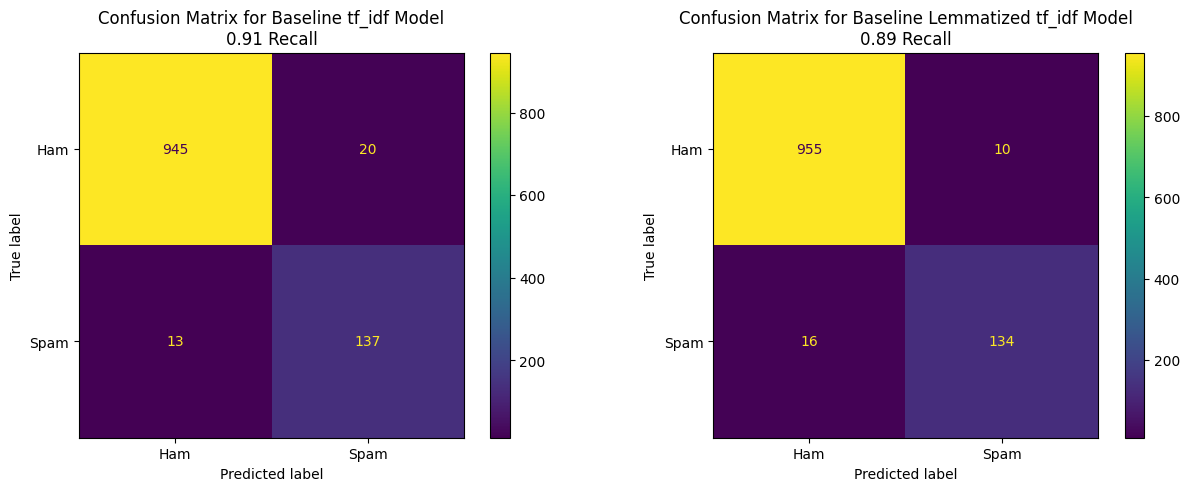

In [266]:
# loading weights
tf_idf_model.load_state_dict(torch.load('weights/tf_idf_model.pth'))
tf_idf_lemmatized_model.load_state_dict(torch.load('weights/lemmatized_tf_idf_model.pth'))

# get predictions
tf_idf_predictions = tf_idf_model.predict(tf_idf_x_test_loader)
tf_idf_lematized_predictions = tf_idf_lemmatized_model.predict(tf_idf_lematized_x_test_loader)

# plot cms
fig , axes = plt.subplots(1, 2, figsize=(15, 5))

# non lemmatized
tf_idf_cm = confusion_matrix(y_test, tf_idf_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=tf_idf_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(f'Confusion Matrix for Baseline tf_idf Model\n{recall_score(y_test, tf_idf_predictions, pos_label=1):.2f} Recall')

# lemmatized
tf_idf_lematized_cm = confusion_matrix(y_test, tf_idf_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=tf_idf_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(f'Confusion Matrix for Baseline Lemmatized tf_idf Model\n{recall_score(y_test, tf_idf_lematized_predictions, pos_label=1):.2f} Recall')

plt.show()

Suprisingly, we see that tf-idf does not perform better than BoW in this case. 


---

## Embedding with GRU, LSTM and BiLSTM

To try to improve performance, we will try to use word embeddings with RNNs such as GRU, LSTM and BiLSTM.

For the Tokenizer, we will be using the `bert-base-uncased` tokenizer from Huggingface.

In [267]:
from transformers import BertTokenizer

tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

In [268]:
# original
tokenized_train = tokenizer(list(X_train), padding=True, truncation=True, return_tensors='pt')
tokenized_test = tokenizer(list(X_test), padding=True, truncation=True, return_tensors='pt')

tokenized_train_dataset = TensorDataset(tokenized_train['input_ids'], torch.tensor(y_train))
tokenized_train_loader = DataLoader(tokenized_train_dataset, batch_size=32, shuffle=True)

tokenized_test_dataset = TensorDataset(tokenized_test['input_ids'], torch.tensor(y_test))
tokenized_test_loader = DataLoader(tokenized_test_dataset, batch_size=32)

# lemmatized
tokenized_train_lematized = tokenizer(list(X_train_lematized), padding=True, truncation=True, return_tensors='pt')
tokenized_test_lematized = tokenizer(list(X_test_lematized), padding=True, truncation=True, return_tensors='pt')

tokenized_train_lematized_dataset = TensorDataset(tokenized_train_lematized['input_ids'], torch.tensor(y_train))
tokenized_train_lematized_loader = DataLoader(tokenized_train_lematized_dataset, batch_size=32, shuffle=True)

tokenized_test_lematized_dataset = TensorDataset(tokenized_test_lematized['input_ids'], torch.tensor(y_test))
tokenized_test_lematized_loader = DataLoader(tokenized_test_lematized_dataset, batch_size=32)

In [269]:
# define LSTM hyperparameter space
lstm_param_space = {
    'input_dim': [32, 64],
    'hidden_dim': [8, 16, 24, 32],
    'output_dim': [2],
    'lr': [1e-4, 1e-2, 1e-03],
    'batch_size': [16, 32, 64, 128],
    'epochs': [20 , 30], 
    'dropout_rate': [0.3, 0.5, 0.7]
}

lstm_selected_params = list(ParameterSampler(lstm_param_space, n_iter=5, random_state=42))

In [270]:
# we build a simple sequential model as baseline
class LSTM_RNN(Model):
  def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.5):
    super().__init__()
    self.embedding = nn.Embedding(num_embeddings=30522, embedding_dim=input_dim, padding_idx=0)
    # Typically Bi LSTM performs better for text classifications
    self.fc1 = nn.LSTM(input_dim, hidden_dim, batch_first=True, bidirectional=True)
    self.dropout = nn.Dropout(dropout_rate)
    self.fc2 = nn.Linear(hidden_dim * 2, 32) # fully connected layer
    self.relu = nn.ReLU()
    self.fc3 = nn.Linear(32 , output_dim)
  
  def forward(self, x):
    x = self.embedding(x)
    _,  (h_n , _) = self.fc1(x)

    # passing front back
    h_forward = h_n[-2,:,:]
    h_backward = h_n[-1,:,:]

    h = torch.concat((h_forward, h_backward), dim=1)

    out = self.dropout(h)
    out = self.fc2(out)
    out = self.relu(out)
    out = self.fc3(out)
    return out

In [271]:
# hyperparameter tuning for LSTM models (original and lemmatized)
lstm_results = []
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for params in lstm_selected_params:
  print(f"Training LSTM with params: {params}")
  
  model = LSTM_RNN
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tokenized_train_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=3
  )
  
  lstm_results.append({
    **params,
    **results
  })
  
# lemmatized data
lstm_lematized_results = []
for params in lstm_selected_params:
  print(f"Training Lemmatized LSTM with params: {params}")
  model = LSTM_RNN
  optimizer = Adam
  loss_fn = nn.CrossEntropyLoss(weight=class_weights)
  results = train_kf(
    model,
    params={
      'input_dim': params['input_dim'],
      'hidden_dim': params['hidden_dim'],
      'output_dim': params['output_dim'],
      'dropout_rate': params['dropout_rate']
    },
    train_loader=tokenized_train_lematized_loader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    kf=kf,
    batch_size=params['batch_size'],
    epochs=params['epochs'],
    early_stop=True,
    patience=3
  )
  
  lstm_lematized_results.append({
    **params,
    **results
  })

Training LSTM with params: {'output_dim': 2, 'lr': 0.0001, 'input_dim': 32, 'hidden_dim': 16, 'epochs': 20, 'dropout_rate': 0.7, 'batch_size': 16}

Fold 1/5
Epoch 1/20, Loss: 0.6802, Accuracy: 86.43%
Epoch 2/20, Loss: 0.4791, Accuracy: 85.70%
Epoch 3/20, Loss: 0.2367, Accuracy: 93.35%
Epoch 4/20, Loss: 0.1531, Accuracy: 96.69%
Epoch 5/20, Loss: 0.1118, Accuracy: 97.78%
Epoch 6/20, Loss: 0.0959, Accuracy: 98.01%
Epoch 7/20, Loss: 0.0654, Accuracy: 98.88%
Epoch 8/20, Loss: 0.0554, Accuracy: 99.07%
Epoch 9/20, Loss: 0.0474, Accuracy: 99.33%
Epoch 10/20, Loss: 0.0405, Accuracy: 99.02%
Epoch 11/20, Loss: 0.0575, Accuracy: 98.71%
Epoch 12/20, Loss: 0.0223, Accuracy: 99.52%
Epoch 13/20, Loss: 0.0101, Accuracy: 99.72%
Epoch 14/20, Loss: 0.0092, Accuracy: 99.72%
Epoch 15/20, Loss: 0.0101, Accuracy: 99.61%
Epoch 16/20, Loss: 0.0053, Accuracy: 99.86%
Epoch 17/20, Loss: 0.0081, Accuracy: 99.80%
Epoch 18/20, Loss: 0.0214, Accuracy: 99.41%
Epoch 19/20, Loss: 0.0104, Accuracy: 99.58%
Early stopping a

In [272]:
lstm_results_df = pd.DataFrame(lstm_results).sort_values(by='f1', ascending=False)
lstm_lematized_results_df = pd.DataFrame(lstm_lematized_results).sort_values(by='f1', ascending=False)

display(lstm_results_df)
display(lstm_lematized_results_df)

,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0010,64,32,20,0.5,16,0.931846,0.944360,0.937560,0.971288
3,2,0.0100,64,16,20,0.7,16,0.937046,0.936724,0.936668,0.970612
0,2,0.0001,32,16,20,0.7,16,0.934637,0.931890,0.933161,0.968818
2,2,0.0001,32,16,30,0.7,32,0.936272,0.927931,0.931920,0.967925
1,2,0.0001,64,8,20,0.3,128,0.915481,0.910568,0.912498,0.958948


,output_dim,lr,input_dim,hidden_dim,epochs,dropout_rate,batch_size,recall,precision,f1,accuracy
4,2,0.0010,64,32,20,0.5,16,0.940369,0.933359,0.936529,0.970168
2,2,0.0001,32,16,30,0.7,32,0.938947,0.934513,0.936318,0.970168
3,2,0.0100,64,16,20,0.7,16,0.943601,0.913705,0.927337,0.964783
0,2,0.0001,32,16,20,0.7,16,0.935408,0.921388,0.926970,0.965233
1,2,0.0001,64,8,20,0.3,128,0.914743,0.914186,0.914262,0.960072


In [273]:
baseline_lstm = LSTM_RNN(input_dim=64, hidden_dim=32, output_dim=2)
lemmatized_baseline_lstm = LSTM_RNN(input_dim=64, hidden_dim=32, output_dim=2)

loss_fn = nn.CrossEntropyLoss(weight=class_weights)
optimizer_lstm = Adam(baseline_lstm.parameters(), lr=1e-03)
lemmatized_optimizer_lstm = Adam(lemmatized_baseline_lstm.parameters(), lr=1e-03)

In [274]:
print('Training Baseline LSTM Model')
with timer('Baseline LSTM Model Training Time'):
  lstm_best_params = lstm_results_df.iloc[0]

  # rebatch with best batch size
  tokenized_train_loader = DataLoader(tokenized_train_dataset, batch_size=int(lstm_best_params['batch_size']), shuffle=True)

  baseline_lstm = LSTM_RNN(
    input_dim=int(lstm_best_params['input_dim']),
    hidden_dim=int(lstm_best_params['hidden_dim']),
    output_dim=int(lstm_best_params['output_dim']),
    dropout_rate=float(lstm_best_params['dropout_rate'])
  )
  optimizer_lstm = Adam(baseline_lstm.parameters(), lr=lstm_best_params['lr'])
  baseline_lstm.fit(int(lstm_best_params['epochs']), tokenized_train_loader, loss_fn, optimizer_lstm, early_stop=True)

print()
print('Training Baseline Lemmatized LSTM Model')
with timer('Baseline Lemmatized LSTM Model Training Time'):
  lstm_lematized_best_params = lstm_lematized_results_df.iloc[0]

  # rebatch with best batch size
  tokenized_train_lematized_loader = DataLoader(tokenized_train_lematized_dataset, batch_size=int(lstm_lematized_best_params['batch_size']), shuffle=True)

  lemmatized_baseline_lstm = LSTM_RNN(
    input_dim=int(lstm_lematized_best_params['input_dim']),
    hidden_dim=int(lstm_lematized_best_params['hidden_dim']),
    output_dim=int(lstm_lematized_best_params['output_dim']),
    dropout_rate=float(lstm_lematized_best_params['dropout_rate'])
  )
  lemmatized_optimizer_lstm = Adam(lemmatized_baseline_lstm.parameters(), lr=lstm_lematized_best_params['lr'])
  lemmatized_baseline_lstm.fit(int(lstm_lematized_best_params['epochs']), tokenized_train_lematized_loader, loss_fn, lemmatized_optimizer_lstm, early_stop=True)

Training Baseline LSTM Model
Epoch 1/20, Loss: 0.5189, Accuracy: 88.27%
Epoch 2/20, Loss: 0.1856, Accuracy: 95.15%
Epoch 3/20, Loss: 0.1130, Accuracy: 97.04%
Epoch 4/20, Loss: 0.0612, Accuracy: 98.68%
Epoch 5/20, Loss: 0.0406, Accuracy: 99.06%
Epoch 6/20, Loss: 0.0317, Accuracy: 99.28%
Epoch 7/20, Loss: 0.0165, Accuracy: 99.55%
Epoch 8/20, Loss: 0.0069, Accuracy: 99.82%
Epoch 9/20, Loss: 0.0045, Accuracy: 99.89%
Epoch 10/20, Loss: 0.0012, Accuracy: 100.00%
Epoch 11/20, Loss: 0.0007, Accuracy: 99.98%
Epoch 12/20, Loss: 0.0004, Accuracy: 100.00%
Epoch 13/20, Loss: 0.0002, Accuracy: 100.00%
Epoch 14/20, Loss: 0.0001, Accuracy: 100.00%
Epoch 15/20, Loss: 0.0003, Accuracy: 100.00%
Epoch 16/20, Loss: 0.0000, Accuracy: 100.00%
Epoch 17/20, Loss: 0.0271, Accuracy: 99.30%
Epoch 18/20, Loss: 0.0207, Accuracy: 99.37%
Epoch 19/20, Loss: 0.0050, Accuracy: 99.84%
Epoch 20/20, Loss: 0.0006, Accuracy: 100.00%
Baseline LSTM Model Training Time: 331.7326s

Training Baseline Lemmatized LSTM Model
Epoch 1

In [275]:
# saving weights
torch.save(baseline_lstm.state_dict(), 'weights/baseline_lstm_model.pth')
torch.save(lemmatized_baseline_lstm.state_dict(), 'weights/baseline_lemmatized_lstm_model.pth')

In [276]:
# loading weights
baseline_lstm.load_state_dict(torch.load('weights/baseline_lstm_model.pth'))
lemmatized_baseline_lstm.load_state_dict(torch.load('weights/baseline_lemmatized_lstm_model.pth'))

# get predictions
baseline_lstm_predictions = baseline_lstm.predict(tokenized_test_loader)
baseline_lstm_lematized_predictions = lemmatized_baseline_lstm.predict(tokenized_test_lematized_loader)

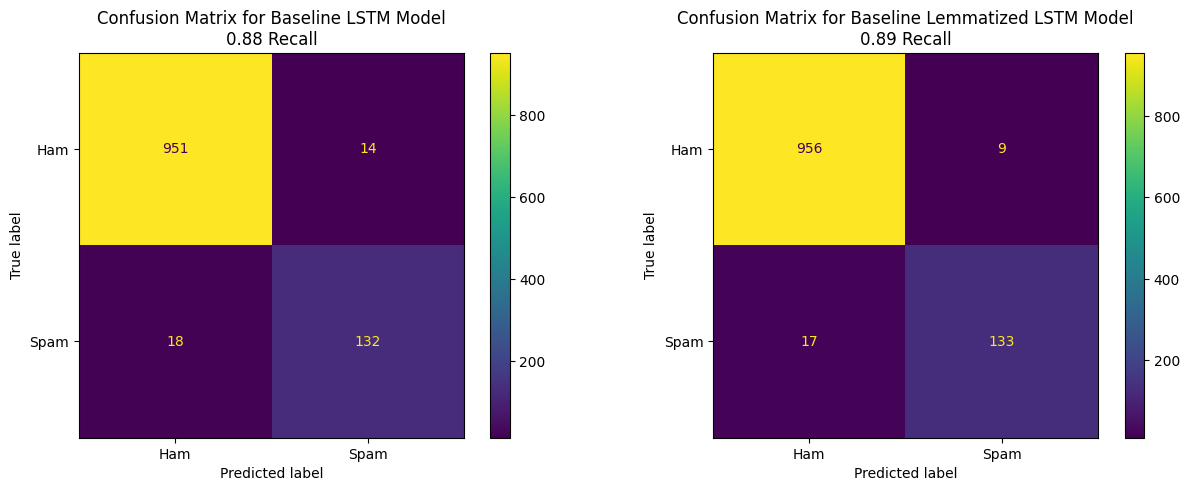

In [277]:
# evaluate baseline LSTM models
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# original
lstm_cm = confusion_matrix(y_test, baseline_lstm_predictions)
disp = ConfusionMatrixDisplay(confusion_matrix=lstm_cm, display_labels=['Ham', 'Spam'])
disp.plot(ax=axes[0])
axes[0].set_title(
    f'Confusion Matrix for Baseline LSTM Model\n{recall_score(y_test, baseline_lstm_predictions, pos_label=1):.2f} Recall'
),

# lemmatized
lstm_lematized_cm = confusion_matrix(y_test, baseline_lstm_lematized_predictions)
disp_lematized = ConfusionMatrixDisplay(confusion_matrix=lstm_lematized_cm, display_labels=['Ham', 'Spam'])
disp_lematized.plot(ax=axes[1])
axes[1].set_title(
    f'Confusion Matrix for Baseline Lemmatized LSTM Model\n{recall_score(y_test, baseline_lstm_lematized_predictions, pos_label=1):.2f} Recall'
),

plt.show()

## Results Comparison

To summarise the results of the variaous models:

|Model|Origianl Data Recall|Lemmatized Data Recall|
|-----|--------------------|---------------------|
|Binary BoW + MLP|0.89|0.92|
|TF-IDF + MLP|0.91|0.89|
|Embedding + LSTM|0.88|0.89|


Surprisingly, the simple Binary BoW + MLP model outperforms the more complex Embedding + LSTM model in terms of recall.

We also see that Binary BoW and TF-IDF perform quite similarly in terms of recall regardless of lemmatization.

**What this can mean?**

1. For spam email detection, simple models like BoW + MLP can be very effective.
2. The data might not have sequential patterns that LSTM can use, making BoW sufficient.
3. Small Dataset size might limit the effectiveness of complex models like LSTM.

### Basic Diagnosis

To further understand, we can try **suffling** the words in the email to see if word order matters.
